# Case Study 21 — "Did Gold Really Raise Frequency?": Measuring a Paid Membership Without Randomisation (Selection Bias, Propensity Matching, Difference-in-Differences)

**Priority:** ★★ Good to have · **Reference:** Case Study 21 — *Zomato Gold relaunch (2023) and Flipkart Plus tiering as membership design* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Loyalty / Subscriptions, Growth, Finance (contribution margin), Product
**Evidence level:** ⚠️ **Weak-to-Medium.** The programme design is documented through press coverage; **no model, experiment or measurement method is public.** This notebook is an interview-standard solution on **simulated data**, not a reproduction of any company's system.
**Data:** ⚠️ **SYNTHETIC** (D-21-01). Customer order histories are confidential; this is a simulation with a hidden ground truth, so every estimator can be graded.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs21_membership_programme_retention.ipynb`

## 0. Executive Summary for Business

«EXEC»

## 1. The Problem in Simple English

A food-delivery app launches a paid membership: pay about ₹50 a month, get free delivery and discounts. Months later someone reports, "**members order far more than non-members**". The temptation is to credit the programme and expand it.

That comparison is not fair. **People who join a membership are the people who were already going to order a lot**, or whose ordering was already rising. They would have ordered more even without Gold. So the raw gap mixes two things: what Gold *caused* and who *chose* Gold. We cannot run a clean A/B test on the whole base, because the programme was open to everyone.

Leaders and interviewers want to know:
1. How big is the **selection bias** in the naive comparison?
2. What does **propensity-score matching** fix, and what can it not fix?
3. When is **difference-in-differences** trustworthy (parallel trends), and how do we check?
4. Does a small **randomised pilot** (a free-trial invitation) give a cleaner answer, and at what price in precision?
5. The real success metric: frequency is up, but is **contribution margin** up after free delivery and discounts?

## 2. Reference from the Case File

### (a) What is documented — *and how thin it is*

| Item | Documented fact (from the reference file) |
|---|---|
| Zomato Gold relaunch | January 2023. CEO Deepinder Goyal said the redesign was built on lessons from past years and is "more sustainable for customers, restaurant partners, and Zomato's P&L". It was expected to "drive loyalty and higher frequency of ordering going forward" |
| Gold design | ₹149 for three months (introductory price); unlimited free delivery within 10 km or on orders above ₹199; "On Time Guarantee" ₹100 coupons for delayed orders; up to 30% off delivery and up to 40% flat off dining at 25,000+ restaurants |
| Scale (company-reported via press) | "Over nine lakh" Gold members within a month of the relaunch (Business Today, 9 Feb 2023) |
| Flipkart Plus (design contrast) | Earned tiers: Silver at 15 and Gold at 25 successful transactions in the last 365 days, auto-activation, SuperCoins of 1 or 2 per ₹100 with caps of 50 per month and 15 per order (Flipkart Stories, 15 Aug 2023) |
| Models, experiments, metrics, thresholds | **Not disclosed (ND).** No public method for how either company measured the effect or set the thresholds |

**Evidence limits.** The shareholder-letter PDFs themselves could not be fetched, so the reference file relies on press coverage. Some figures that circulate (a frequency uplift after joining, the share of GOV from members, Swiggy One comparisons) appeared only in search snippets and are **unverified; this notebook does not use them.** Public method detail is thin, so everything below the design facts is **our own interview-standard solution on simulated data**.

**Sources:** Business Today, 9 Feb 2023 and 22 Mar 2023, reporting Zomato's Q3 FY23 letter; Flipkart Stories, 15 Aug 2023.

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 40,000 customers × 24 months. The programme launches in month 12. Customers **choose** to join, with probability rising with **recent orders, recent growth, fee sensitivity, coupon use and a hidden "momentum" trait**. Members order about 11% more (hidden truth), lapse less, but each member order costs a delivery subsidy. Half the customers got a randomised free-trial invitation at launch (the pilot). |
| Hidden truth | Counterfactual orders and contribution if nobody had joined, so we can grade each estimator against the real effect |
| Methods compared | Naive comparisons; **propensity-score matching** (levels only vs levels plus trend); **difference-in-differences** with an event study; the **randomised pilot** (instrumental variable / Wald); heterogeneity; a small uplift model |
| Statistics added | Standardised mean differences, propensity AUC and overlap, matched ATT with confidence intervals, **parallel-trend placebo tests**, event study, first-stage strength (F), **Holm** correction for subgroups, power and sample size for a proper holdout |

### (c) How the industry uses this

Every subscription programme (Swiggy One, Zomato Gold, Amazon Prime, Flipkart Plus, Myntra Insider) faces the same question. Typical practice: **a persistent holdout** where possible, **matching or diff-in-diff** when not, and **contribution margin per customer**, not GOV, as the success metric. It is a regular interview topic for growth and analytics roles because it tests whether you spot selection bias.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Does the membership raise order frequency and loyalty without destroying unit economics, and should it be expanded, re-priced or targeted? |
| Analytical | What is the **causal effect on members** (ATT) on orders per month, retention and contribution margin per month, once self-selection is handled? |

**Hypotheses**
- **H1 (selection):** H0: eventual members and never-members have the same pre-launch order level and trend (SMD, Welch t, propensity AUC = 0.5).
- **H2 (frequency):** H0: ATT on orders per month = 0 under matching and under difference-in-differences. **Parallel-trend placebo:** H0: the DiD on a fake launch inside the pre-period = 0.
- **H3 (margin):** H0: ATT on contribution margin per customer-month = 0 (members' fee, subsidy and extra orders netted).
- **H4 (heterogeneity):** H0: the margin effect is the same across customer groups (Holm over 6 subgroup tests).
- **H5 (pilot):** H0: the free-trial invitation does not change joining (first stage), and the instrumented effect on orders = 0.

**Primary metrics:** orders per customer-month, active in the last 3 months of the window (retention), **contribution margin per customer-month**. **Secondary:** GOV. **Design:** treated = joined in the launch month; control = never joined; both active in months 9 to 11 and **not** in the invitation pilot; pre window months 6 to 11, post window months 12 to 17.

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neighbors import NearestNeighbors

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public Indian food-delivery order and membership logs | **None.** Customer order histories and membership data are confidential. |
| Public method description of the company measurement | **None** (shareholder-letter PDFs not retrievable; press coverage reports programme design and headline counts only) |
| **Decision** | Synthetic customer-month panel with a hidden counterfactual, so selection bias can be shown and every estimator graded (D-21-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs21.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 21 (paid food-delivery membership: Zomato Gold style)
===========================================================================================
THIS DATA IS SYNTHETIC. Customer order histories and membership data are confidential, and no public method is
documented for how Zomato or Flipkart measured their programmes.

Documented context only (see the reference file): Zomato relaunched Gold in January 2023 at Rs 149 for three months
(introductory price), with free delivery within 10 km or above Rs 199 and on-time-guarantee coupons; over nine lakh
members within a month of relaunch (company-reported via press). Everything else below is our assumption.

Simulation: 40,000 customers x 24 months. The programme launches in month 12.
  * Each customer has a base order rate, a hidden momentum term u (a customer whose eating-out/ordering is growing),
    a fee-sensitivity feature and a hidden true treatment effect tau (log-rate lift from membership).
  * Customers choose to join: the probability rises with RECENT realised orders, recent growth, fee sensitivity,
    coupon use and the hidden momentum u. That is self-selection on levels, on trend and on something unobserved.
  * Members order more (log-rate lift tau, about +11 percent on average), lapse less, but each member order costs a
    delivery subsidy, and the member pays Rs 149 per three months.
  * A randomised pilot: half of the customers got a one-month free-trial invitation at launch (offer = 1), which
    raises the chance of joining in month 12 only.
Hidden truth (columns starting with an underscore): counterfactual orders and contribution if nobody joined (computed
with common random numbers), the hidden momentum u and the true effect tau. They are used only to grade the estimators.

Outputs: data/cs21/panel.csv.gz (customer-month), data/cs21/customers.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.stats import poisson

SEED = 42
N, T, L = 40_000, 24, 12
FEE_PER_MONTH = 149 / 3
MARGIN_RATE = 0.13


def _sig(x):
    return 1 / (1 + np.exp(-x))


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    tier = rng.choice([1, 2, 3], N, p=[0.45, 0.35, 0.20])
    za = rng.normal(0, 1, N)
    a = np.log(2.0) + 0.65 * za + 0.15 * (tier == 1)
    aov = np.exp(rng.normal(np.log(400), 0.30, N) + 0.10 * (tier == 1))
    fee = np.clip(rng.beta(2, 3, N), 0, 1)
    coupon = np.clip(rng.beta(2, 5, N) + 0.05 * fee, 0, 1)
    tenure = np.round(rng.exponential(14, N) + 1).astype(int)
    u = rng.normal(0, 1, N)
    g = 0.22 * u
    offer = (rng.random(N) < 0.5).astype(int)
    tau = np.clip(0.11 + 0.05 * (fee - 0.4) / 0.2 - 0.03 * za + rng.normal(0, 0.03, N), -0.02, 0.40)
    subsidy = 18 + 25 * fee
    margin = MARGIN_RATE * aov
    season = 0.08 * np.sin(2 * np.pi * np.arange(T) / 12)
    Ul, Up = rng.random((N, T)), rng.random((N, T))
    Ug = rng.lognormal(0, 0.10, (N, T))

    orders = np.zeros((N, T), int); cf = np.zeros((N, T), int); mem = np.zeros((N, T), int)
    act = np.ones(N, bool); act_cf = np.ones(N, bool); member = np.zeros(N, bool); join = np.full(N, -1)
    hist_log = np.zeros((N, T))
    for t in range(T):
        lr = a + g * (t - 11) / 12 + season[t]
        haz0 = _sig(-3.9 - 0.45 * za - 0.30 * u)
        mu = np.exp(lr + tau * member)
        haz = _sig(-3.9 - 0.45 * za - 0.30 * u - 0.40 * member)
        act = act & (Ul[:, t] > haz); act_cf = act_cf & (Ul[:, t] > haz0)
        orders[:, t] = np.where(act, poisson.ppf(Up[:, t], mu), 0)
        cf[:, t] = np.where(act_cf, poisson.ppf(Up[:, t], np.exp(lr)), 0)
        mem[:, t] = member
        hist_log[:, t] = np.log1p(orders[:, t])
        # joining happens at the start of month t+1 (t >= L-1): uses realised history through t
        if t >= L - 1 and t < T - 1:
            recent = hist_log[:, max(0, t - 2):t + 1].mean(1); prior = hist_log[:, max(0, t - 5):max(1, t - 2)].mean(1)
            z_recent = (recent - 1.0) / 0.7; growth = (recent - prior) / 0.4
            first = (t == L - 1)
            logit = (-3.5 if not first else -2.4) + 0.45 * z_recent + 0.55 * growth + 0.45 * u + 0.30 * (tier == 1) \
                + 0.9 * (fee - 0.4) / 0.2 * 0.25 + 0.6 * (coupon - 0.3) / 0.15 * 0.25 + (1.8 * offer if first else 0.0)
            p = _sig(logit) * act * (~member)
            new = rng.random(N) < p
            join[new] = t + 1; member = member | new
    mu_gov = Ug * aov[:, None] * (1 + 0.03 * mem)
    gov = np.round(orders * mu_gov, 0)
    sub = orders * mem * subsidy[:, None]
    contrib = orders * margin[:, None] - sub + mem * FEE_PER_MONTH
    contrib_cf = cf * margin[:, None]
    cid = np.repeat(np.arange(N), T); mo = np.tile(np.arange(T), N)
    panel = pd.DataFrame({"customer_id": cid, "month": mo, "orders": orders.ravel(), "gov_inr": gov.ravel(), "member": mem.ravel(),
                          "delivery_subsidy_inr": np.round(sub.ravel(), 1), "contribution_inr": np.round(contrib.ravel(), 1),
                          "_orders_cf": cf.ravel(), "_contribution_cf": np.round(contrib_cf.ravel(), 1)})
    cust = pd.DataFrame({"customer_id": np.arange(N), "city_tier": tier, "fee_paid_share": np.round(fee, 3), "coupon_share": np.round(coupon, 3),
                         "tenure_months": tenure, "offer": offer, "join_month": np.where(join >= 0, join, np.nan),
                         "_u": np.round(u, 3), "_tau": np.round(tau, 4), "_subsidy_per_order": np.round(subsidy, 1), "_margin_per_order": np.round(margin, 1)})
    # messy-data defects
    dup = panel.sample(n=1500, random_state=seed)
    cust.loc[cust.sample(frac=0.05, random_state=seed).index, "city_tier"] = np.nan
    staff = pd.DataFrame({"customer_id": np.repeat(np.arange(N, N + 25), T), "month": np.tile(np.arange(T), 25)})
    staff["orders"] = rng.integers(60, 140, len(staff)); staff["gov_inr"] = staff.orders * 380.0; staff["member"] = (staff.month >= L).astype(int)
    staff["delivery_subsidy_inr"] = 0.0; staff["contribution_inr"] = 0.0; staff["_orders_cf"] = staff.orders; staff["_contribution_cf"] = 0.0
    panel = pd.concat([panel, dup, staff], ignore_index=True).sort_values(["customer_id", "month"]).reset_index(drop=True)
    return panel, cust


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs21"), exist_ok=True)
    p, c = generate(); p.to_csv(os.path.join(here, "cs21", "panel.csv.gz"), index=False); c.to_csv(os.path.join(here, "cs21", "customers.csv.gz"), index=False)
    print(len(p), len(c), c.join_month.value_counts().sort_index().to_dict())

Overwriting data/generate_cs21.py


In [3]:
os.makedirs("data/cs21", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs21 as gen; importlib.reload(gen)
t0 = time.time(); panel_raw, cust_raw = gen.generate(seed=SEED)
panel_raw.to_csv("data/cs21/panel.csv.gz", index=False); cust_raw.to_csv("data/cs21/customers.csv.gz", index=False)
print(f"{len(panel_raw):,} customer-month rows | {len(cust_raw):,} customers | generated in {time.time() - t0:.0f}s")
panel_raw.head(4)

962,100 customer-month rows | 40,000 customers | generated in 189s


,customer_id,month,orders,gov_inr,member,delivery_subsidy_inr,contribution_inr,_orders_cf,_contribution_cf
0,0,0,3,"1,322.0000",0,0.0000,172.7000,3,172.7000
1,0,1,1,490.0000,0,0.0000,57.6000,1,57.6000
2,0,2,6,"2,524.0000",0,0.0000,345.5000,6,345.5000
3,0,3,3,"1,161.0000",0,0.0000,172.7000,3,172.7000


| Parameter | Value | Basis |
|---|---|---|
| Scale | 40,000 customers, 24 months, launch in month 12 | Our assumption (Zomato: over nine lakh members within a month, company-reported) |
| Fee | ₹149 per three months (≈ ₹50 a month) | **Documented** introductory price |
| Free delivery | Each member order costs ₹18 to ₹43 of delivery subsidy and discount, higher for fee-sensitive customers | Our assumption |
| Margin before subsidy | 13% of basket value (≈ ₹52 per order) | Our assumption |
| Frequency effect | log-rate lift of about +11% on average (hidden, varies by customer) | Our assumption (hidden truth) |
| Selection | Joining odds rise with last-3-month orders, growth, fee sensitivity, coupon use and a hidden momentum trait | Our assumption (the point of the exercise) |
| Pilot | Random half invited to a free trial at launch; raises joining in month 12 only | Our assumption |
| Lapse | Monthly hazard about 2%; membership lowers the log-odds by 0.4 | Our assumption |
| DQ issues | 1,500 duplicate rows; 25 staff/test accounts; 5% missing city tier | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("panel: customer_id, month", "Customer and month index 0 to 23 (launch in month 12)"), ("orders, gov_inr", "Orders and gross order value in the month"),
    ("member", "1 if the customer was a paying member that month"), ("delivery_subsidy_inr", "Delivery fee and discount given to members on their orders"),
    ("contribution_inr", "Contribution margin of the month: orders × margin − subsidy + membership fee share"),
    ("customers: city_tier, fee_paid_share, coupon_share, tenure_months", "Tier (blank = unknown), share of orders that paid a delivery fee, share of orders with a coupon, months since first order"),
    ("offer, join_month", "Free-trial invitation at launch (random); month of joining (blank = never)"),
    ("_orders_cf, _contribution_cf, _u, _tau, _subsidy_per_order, _margin_per_order", "HIDDEN: counterfactual orders and contribution, momentum, true effect (grading only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs21/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"panel: customer_id, month",Customer and month index 0 to 23 (launch in mo...
1,"orders, gov_inr",Orders and gross order value in the month
2,member,1 if the customer was a paying member that month
3,delivery_subsidy_inr,Delivery fee and discount given to members on ...
4,contribution_inr,Contribution margin of the month: orders × mar...
5,"customers: city_tier, fee_paid_share, coupon_s...","Tier (blank = unknown), share of orders that p..."
6,"offer, join_month",Free-trial invitation at launch (random); mont...
7,"_orders_cf, _contribution_cf, _u, _tau, _subsi...",HIDDEN: counterfactual orders and contribution...


## 5. Data Quality Checks

In [5]:
avg_o = panel_raw.groupby("customer_id").orders.mean()
chk_m = panel_raw.drop_duplicates(["customer_id", "month"]).merge(cust_raw[["customer_id", "join_month"]], on="customer_id", how="inner")
checks = {"duplicate customer-month rows": int(panel_raw.duplicated(["customer_id", "month"]).sum()),
          "staff/test-like accounts (> 30 orders a month on average)": int((avg_o > 30).sum()),
          "customers with missing city tier": int(cust_raw.city_tier.isna().sum()),
          "member flag disagrees with join_month": int((chk_m.member != (chk_m.month >= chk_m.join_month.fillna(99)).astype(int)).sum())}
print(pd.Series(checks, name="rows").to_string())
panel = panel_raw.drop_duplicates(["customer_id", "month"]); panel = panel[~panel.customer_id.isin(avg_o[avg_o > 30].index)]
cust = cust_raw.copy(); cust["city_tier"] = cust.city_tier.fillna(0).astype(int)
truth = panel[["customer_id", "month", "_orders_cf", "_contribution_cf"]].copy(); ctruth = cust.set_index("customer_id")[["_u", "_tau"]]
panel = panel.drop(columns=[c for c in panel.columns if c.startswith("_")]); cust = cust.drop(columns=[c for c in cust.columns if c.startswith("_")])
wide = lambda df, col: df.pivot(index="customer_id", columns="month", values=col).sort_index()
O, G, C, MEM = (wide(panel, c) for c in ("orders", "gov_inr", "contribution_inr", "member")); OCF, CCF = wide(truth, "_orders_cf"), wide(truth, "_contribution_cf")
print(f"\nClean: {len(O):,} customers × {O.shape[1]} months | members at month 23: {MEM[23].mean():.1%} | joined in launch month: {(cust.join_month == 12).sum():,} | never joined: {cust.join_month.isna().sum():,}")

duplicate customer-month rows                                1500
staff/test-like accounts (> 30 orders a month on average)      28
customers with missing city tier                             2000
member flag disagrees with join_month                           0



Clean: 39,997 customers × 24 months | members at month 23: 41.6% | joined in launch month: 8,429 | never joined: 23,377


**Observation:** «O5»

## 6. Exploratory Data Analysis

Observational sample: 15,502 active, un-invited customers; dropped 4,927 who joined after the launch month; kept 10,575: 1,981 launch-month members vs 8,594 never-members


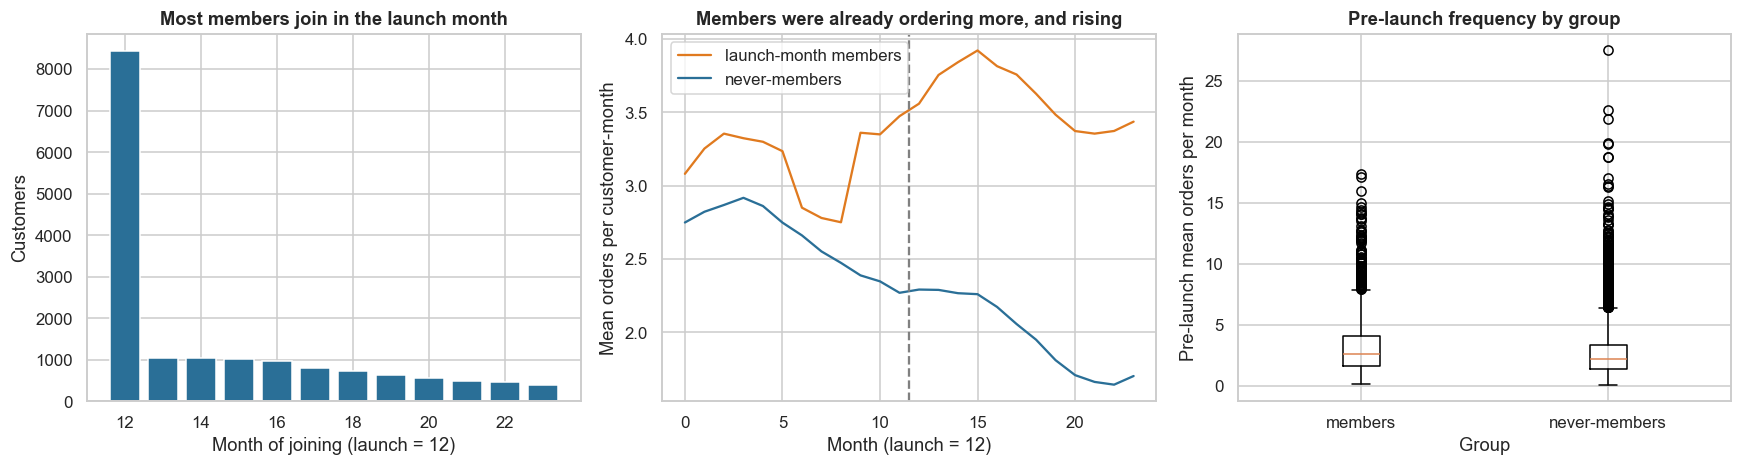

Pre-launch (months 0-11) mean orders: members 3.18 vs never-members 2.64; last three pre-launch months: 3.39 vs 2.33


In [6]:
# analyst features from the PRE-launch window only (months 0 to 11)
F = pd.DataFrame(index=O.index); pre = list(range(12)); mm6 = np.arange(6) - 2.5
F["o12"] = O[pre].mean(1); F["o3"] = O[[9, 10, 11]].mean(1); F["growth"] = F.o3 - O[[6, 7, 8]].mean(1); F["slope6"] = (O.loc[:, 6:11].values * mm6).sum(1) / (mm6 ** 2).sum()
F["aov_pre"] = G[pre].sum(1) / O[pre].sum(1).clip(lower=1)
F = F.join(cust.set_index("customer_id")[["city_tier", "fee_paid_share", "coupon_share", "tenure_months", "offer", "join_month"]])
F["tier1"] = (F.city_tier == 1).astype(int); F["tier2"] = (F.city_tier == 2).astype(int); F["tierU"] = (F.city_tier == 0).astype(int)
F["active_recent"] = O[[9, 10, 11]].sum(1) > 0
# outcomes: pre window months 6-11, post window months 12-17
F["ypre"], F["ypost"] = O.loc[:, 6:11].mean(1), O.loc[:, 12:17].mean(1); F["dy"] = F.ypost - F.ypre
F["gpre"], F["gpost"] = G.loc[:, 6:11].mean(1), G.loc[:, 12:17].mean(1); F["dg"] = F.gpost - F.gpre
F["cpre"], F["cpost"] = C.loc[:, 6:11].mean(1), C.loc[:, 12:17].mean(1); F["dc"] = F.cpost - F.cpre
F["ret"] = (O[[15, 16, 17]].sum(1) > 0).astype(int)
S = F[F.active_recent & (F.offer == 0)].copy(); n_elig = len(S); n_later = int((S.join_month > 12).sum())
S = S[(S.join_month == 12) | S.join_month.isna()].copy(); S["treat"] = (S.join_month == 12).values; T = S.treat.values
print(f"Observational sample: {n_elig:,} active, un-invited customers; dropped {n_later:,} who joined after the launch month; kept {len(S):,}: {T.sum():,} launch-month members vs {(~T).sum():,} never-members")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
jm = cust.join_month.value_counts().sort_index(); axes[0].bar(jm.index.astype(int), jm.values, color="#2a6f97"); axes[0].set_xlabel("Month of joining (launch = 12)"); axes[0].set_ylabel("Customers"); axes[0].set_title("Most members join in the launch month")
OSx = O.loc[S.index].values
axes[1].plot(range(24), OSx[T].mean(0), color="#e07a1f", label="launch-month members"); axes[1].plot(range(24), OSx[~T].mean(0), color="#2a6f97", label="never-members"); axes[1].axvline(11.5, color="grey", ls="--"); axes[1].set_xlabel("Month (launch = 12)"); axes[1].set_ylabel("Mean orders per customer-month"); axes[1].set_title("Members were already ordering more, and rising"); axes[1].legend()
axes[2].boxplot([S.o12[T], S.o12[~T]], labels=["members", "never-members"]); axes[2].set_xlabel("Group"); axes[2].set_ylabel("Pre-launch mean orders per month"); axes[2].set_title("Pre-launch frequency by group")
plt.tight_layout(); plt.show()
print(f"Pre-launch (months 0-11) mean orders: members {S.o12[T].mean():.2f} vs never-members {S.o12[~T].mean():.2f}; last three pre-launch months: {S.o3[T].mean():.2f} vs {S.o3[~T].mean():.2f}")

**Takeaway:** «O61»

## 7. Statistical Analysis (core section)

### 7.1 The naive comparisons, and why they mislead

**(a) Why?** Two shortcuts are common: **members vs non-members after launch** (cross-section), and **members before vs after** joining (pre/post). Both are biased: the first by who chooses to join, the second by trends and mean reversion. A **placebo** shows the first bias directly: the same gap measured *before* the programme existed.

#### Code

In [7]:
def welch(x, y):
    d = x.mean() - y.mean(); se = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y)); return d, d - 1.96 * se, d + 1.96 * se, 2 * stats.norm.sf(abs(d / se))
def att_w(y, ti, ci):
    n = len(ti); w = np.bincount(ci, minlength=len(y)).astype(float); est = y[ti].mean() - (w * y).sum() / n; vc = y[np.unique(ci)].var(ddof=1)
    se = np.sqrt(y[ti].var(ddof=1) / n + (w ** 2).sum() * vc / n ** 2); return est, est - 1.96 * se, est + 1.96 * se, 2 * stats.norm.sf(abs(est / se))
RES = {}; tr_all, co_all = np.where(T)[0], np.where(~T)[0]; tpost_mean = S.ypost[T].mean(); ctrl_post = S.ypost[~T].mean()
x_cs = welch(S.ypost[T], S.ypost[~T]); x_pl = welch(S.ypre[T], S.ypre[~T]); se_pp = S.dy[T].std(ddof=1) / np.sqrt(T.sum()); x_pp = (S.dy[T].mean(), S.dy[T].mean() - 1.96 * se_pp, S.dy[T].mean() + 1.96 * se_pp, 2 * stats.norm.sf(abs(S.dy[T].mean() / se_pp)))
RES["naive cross-section"] = x_cs[:3]; RES["naive pre/post"] = x_pp[:3]
nv = pd.DataFrame([("Members − never-members, post-launch months 12-17", *x_cs, x_cs[0] / ctrl_post), ("Same gap BEFORE launch, months 6-11 (placebo)", *x_pl, x_pl[0] / S.ypre[~T].mean()), ("Members: after − before (pre/post)", *x_pp, x_pp[0] / S.ypre[T].mean())],
                  columns=["comparison (orders per customer-month)", "difference", "CI low", "CI high", "p-value", "relative size"]).set_index("comparison (orders per customer-month)")
print(f"Mean post-launch orders: members {tpost_mean:.2f} vs never-members {ctrl_post:.2f}")
nv.round(4)

Mean post-launch orders: members 3.78 vs never-members 2.22

,difference,CI low,CI high,p-value,relative size
comparison (orders per customer-month),,,,,
"Members − never-members, post-launch months 12-17",1.5531,1.4229,1.6833,0.0000,0.6989
"Same gap BEFORE launch, months 6-11 (placebo)",0.6459,0.5403,0.7515,0.0000,0.2638
Members: after − before (pre/post),0.6815,0.6201,0.7429,0.0000,0.2203


**Observation:** «O71»

### 7.2 Who joins? Selection diagnostics and the propensity score

**(a) Why?** Matching needs a **propensity score**: the probability of joining given what we saw before launch. We compare two sets of pre-launch covariates: **levels only** (v1: average frequency, basket size, fee-paid share, coupon share, tenure, city tier) and **levels plus recent trend** (v2: adds last-3-month orders, 3-month growth and 6-month slope). We report each covariate's **standardised mean difference** (SMD; |SMD| < 0.1 is balanced), the cross-validated **AUC** (0.5 = no selection), and **overlap** (treated and control scores must share support).

#### Code

Cross-validated AUC of the join model: {'v1 levels': 0.633, 'v2 levels + trend': 0.728, 'GBM on v2 (default settings)': 0.701}
Overlap (share of controls inside the treated 1st-99th percentile range of the v2 logit score): 91.7%


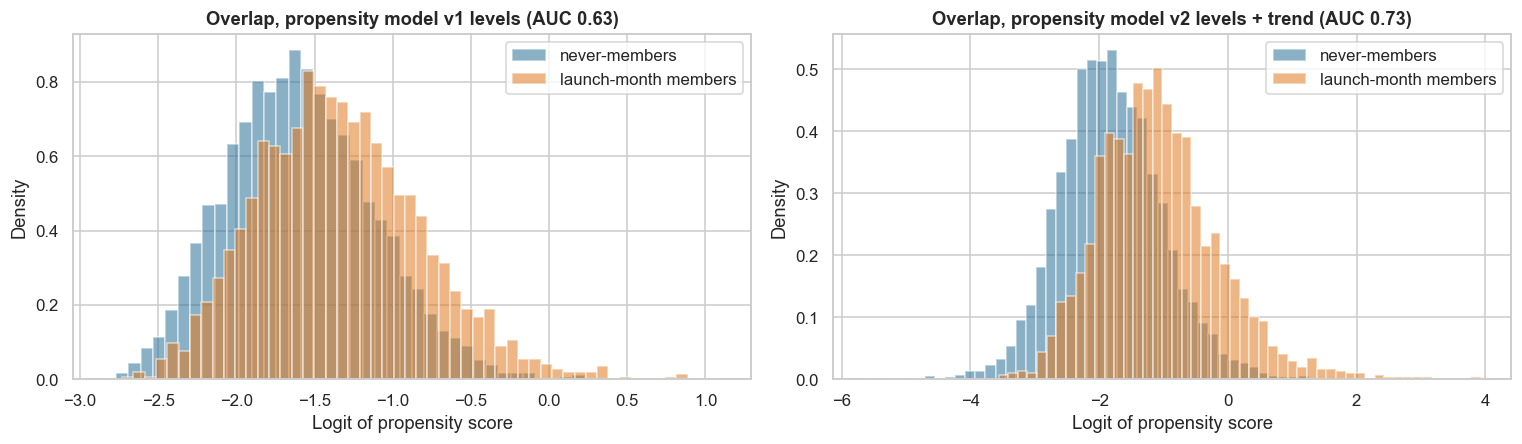

,treated mean,control mean,SMD (raw)
o12,3.1760,2.6380,0.2530
aov_pre,441.9670,440.0670,0.0140
fee_paid_share,0.4320,0.3730,0.2960
coupon_share,0.3310,0.2900,0.2510
tenure_months,14.8410,14.8830,-0.0030
tier1,0.4920,0.3890,0.2090
tier2,0.2970,0.3630,-0.1410
tierU,0.0540,0.0480,0.0250
o3,3.3950,2.3350,0.4960
growth,0.6020,-0.2270,0.6150


In [8]:
V1 = ["o12", "aov_pre", "fee_paid_share", "coupon_share", "tenure_months", "tier1", "tier2", "tierU"]; V2 = V1 + ["o3", "growth", "slope6"]
cv = StratifiedKFold(5, shuffle=True, random_state=SEED); PS = {}; auc = {}
for nm, V in (("v1 levels", V1), ("v2 levels + trend", V2)):
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)); PS[nm] = lr.fit(S[V], T).predict_proba(S[V])[:, 1]
    auc[nm] = roc_auc_score(T, cross_val_predict(lr, S[V], T, cv=cv, method="predict_proba")[:, 1])
auc["GBM on v2 (default settings)"] = roc_auc_score(T, cross_val_predict(HistGradientBoostingClassifier(random_state=SEED), S[V2], T, cv=cv, method="predict_proba")[:, 1])
smd = lambda x, a, b: (x[a].mean() - x[b].mean()) / np.sqrt((x[a].var(ddof=1) + x[b].var(ddof=1)) / 2)
bal = pd.DataFrame({v: {"treated mean": S[v][T].mean(), "control mean": S[v][~T].mean(), "SMD (raw)": smd(S[v].values, T, ~T)} for v in V2}).T
print("Cross-validated AUC of the join model:", {k: round(v, 3) for k, v in auc.items()})
lp = {k: np.log(p / (1 - p)) for k, p in PS.items()}
print("Overlap (share of controls inside the treated 1st-99th percentile range of the v2 logit score): %.1f%%" % (100 * ((lp["v2 levels + trend"][~T] >= np.percentile(lp["v2 levels + trend"][T], 1)) & (lp["v2 levels + trend"][~T] <= np.percentile(lp["v2 levels + trend"][T], 99))).mean()))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (nm, p) in zip(axes, PS.items()):
    ax.hist(np.log(p[~T] / (1 - p[~T])), bins=50, density=True, alpha=0.55, color="#2a6f97", label="never-members"); ax.hist(np.log(p[T] / (1 - p[T])), bins=50, density=True, alpha=0.55, color="#e07a1f", label="launch-month members")
    ax.set_xlabel("Logit of propensity score"); ax.set_ylabel("Density"); ax.set_title(f"Overlap, propensity model {nm} (AUC {auc[nm]:.2f})"); ax.legend()
plt.tight_layout(); plt.show()
bal.round(3)

**Takeaway:** «O72»

### 7.3 Propensity-score matching

**(a) Why?** For each member we pick the **never-member with the closest propensity score** (1 nearest neighbour, with replacement, caliper 0.2 standard deviations of the logit score). If the pre-launch covariates capture why people join, matched pairs are comparable. **(b) Assumption (conditional independence):** nothing unobserved drives both joining and ordering. We cannot test it, but we can see how the estimate moves when trend covariates are added, and we later grade it against the truth. Standard errors treat control reuse through weights (conditional on the match; they ignore uncertainty in the score).

#### Code

Cross-sectional matched effect on post-launch orders per customer-month (months 12-17):


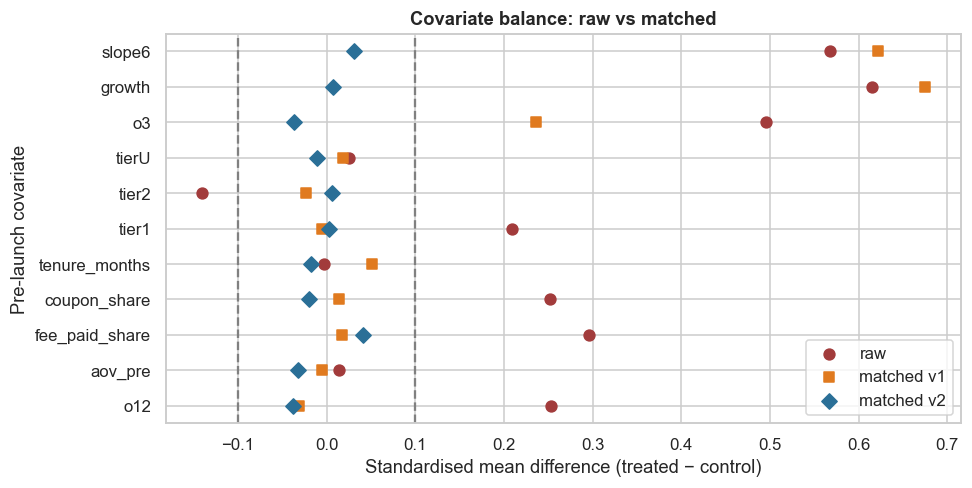

,treated matched,treated total,distinct controls used,max |SMD| after (v2 covariates),ATT orders/month (post),CI low,CI high,p-value,relative to matched controls
propensity model,,,,,,,,,
v1 levels,1981,1981,1621,0.6751,1.0962,0.9177,1.2746,0.0000,0.4091
v2 levels + trend,1975,1981,1496,0.0404,0.9165,0.7314,1.1015,0.0000,0.3244


In [9]:
def match(lp_, caliper_sd=0.2):
    cal = caliper_sd * lp_.std(); nn = NearestNeighbors(n_neighbors=1).fit(lp_[co_all, None]); d, i = nn.kneighbors(lp_[tr_all, None]); ok = d[:, 0] <= cal; return tr_all[ok], co_all[i[ok, 0]]
MT = {k: match(v) for k, v in lp.items()}; rows = []
for nm, (ti, ci) in MT.items():
    e = att_w(S.ypost.values, ti, ci); RES["PSM " + nm.split()[0]] = e[:3]
    rows.append((nm, len(ti), T.sum(), len(np.unique(ci)), max(abs(smd(S[v].values, ti, ci)) for v in V2), *e, e[0] / (S.ypost.values[ci].mean())))
pm = pd.DataFrame(rows, columns=["propensity model", "treated matched", "treated total", "distinct controls used", "max |SMD| after (v2 covariates)", "ATT orders/month (post)", "CI low", "CI high", "p-value", "relative to matched controls"]).set_index("propensity model")
print("Cross-sectional matched effect on post-launch orders per customer-month (months 12-17):")
bal_after = pd.DataFrame({"raw": [smd(S[v].values, T, ~T) for v in V2], "matched v1": [smd(S[v].values, *MT["v1 levels"]) for v in V2], "matched v2": [smd(S[v].values, *MT["v2 levels + trend"]) for v in V2]}, index=V2)
fig, ax = plt.subplots(figsize=(9, 4.6))
for col, mk, cl in (("raw", "o", "#a23b3b"), ("matched v1", "s", "#e07a1f"), ("matched v2", "D", "#2a6f97")): ax.scatter(bal_after[col], range(len(V2)), marker=mk, color=cl, label=col, s=50)
ax.axvline(0.1, color="grey", ls="--"); ax.axvline(-0.1, color="grey", ls="--"); ax.set_yticks(range(len(V2))); ax.set_yticklabels(V2); ax.set_xlabel("Standardised mean difference (treated − control)"); ax.set_ylabel("Pre-launch covariate"); ax.set_title("Covariate balance: raw vs matched"); ax.legend()
plt.tight_layout(); plt.show()
pm.round(4)

**Takeaway:** «O73»

### 7.4 Difference-in-differences and the event study

**(a) Why?** DiD compares each group's **change** from the pre window to the post window, so any stable difference between members and non-members cancels. **(b) Assumption (parallel trends):** without the programme the two groups' orders would have moved in parallel. We test this with an **event study** (the gap in orders by month relative to each group's months 6 to 11 average; the pre-launch months should hover near zero) and a **placebo DiD** on a fake launch inside the pre-period (months 0-2 → 3-5). We run DiD three ways: all controls, matched v1, matched v2.

#### Code

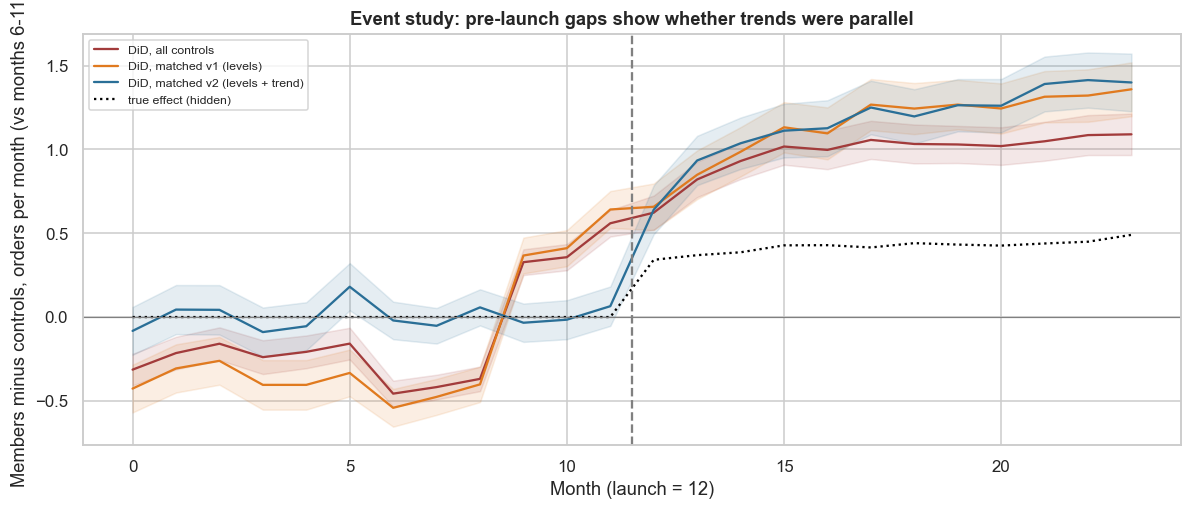

,ATT orders/month,CI low,CI high,p-value,placebo DiD (months 0-2 → 3-5),placebo p-value
design,,,,,,
"DiD, all controls",0.9072,0.8404,0.9741,0.0000,0.0274,0.4547
"DiD, matched v1 (levels)",0.9976,0.9026,1.0925,0.0000,-0.0493,0.3542
"DiD, matched v2 (levels + trend)",1.0161,0.9160,1.1162,0.0000,0.0105,0.8474


In [10]:
OS = O.loc[S.index].values; ref = OS[:, 6:12].mean(1); dy = S.dy.values; plc = OS[:, 3:6].mean(1) - OS[:, 0:3].mean(1)
def design(kind):
    if kind == "all": return lambda y: welch(pd.Series(y[tr_all]), pd.Series(y[co_all]))
    ti, ci = MT[kind]; return lambda y: att_w(y, ti, ci)
DD = {"DiD, all controls": "all", "DiD, matched v1 (levels)": "v1 levels", "DiD, matched v2 (levels + trend)": "v2 levels + trend"}; rows = []; ES = {}
for nm, kind in DD.items():
    f = design(kind); e = f(dy); p = f(plc); RES[nm] = e[:3]; ES[nm] = np.array([f(OS[:, k] - ref)[:3] for k in range(24)])
    rows.append((nm, *e, p[0], p[3]))
dtab = pd.DataFrame(rows, columns=["design", "ATT orders/month", "CI low", "CI high", "p-value", "placebo DiD (months 0-2 → 3-5)", "placebo p-value"]).set_index("design")
OCFS = OCF.loc[S.index].values; true_path = (OS[T] - OCFS[T]).mean(0)
fig, ax = plt.subplots(figsize=(11, 4.8))
for (nm, arr), cl in zip(ES.items(), ("#a23b3b", "#e07a1f", "#2a6f97")): ax.plot(range(24), arr[:, 0], color=cl, label=nm); ax.fill_between(range(24), arr[:, 1], arr[:, 2], color=cl, alpha=0.12)
ax.plot(range(24), true_path, color="black", ls=":", label="true effect (hidden)"); ax.axvline(11.5, color="grey", ls="--"); ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Month (launch = 12)"); ax.set_ylabel("Members minus controls, orders per month (vs months 6-11)"); ax.set_title("Event study: pre-launch gaps show whether trends were parallel"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
dtab.round(4)

**Takeaway:** «O74»

### 7.5 The randomised pilot: free-trial invitation as an instrument

**(a) Why?** At launch a random half of customers got a one-month free-trial invitation. Randomisation removes selection, but the invitation only moves some people (**compliers**), so we use it as an **instrument**: the Wald estimate = (effect of the invitation on orders) / (effect of the invitation on joining in the launch month). **(b) Checks:** the invitation really is random (balance on pre-launch covariates), and it moves joining strongly (**first-stage F > 10**). The price of randomisation is precision, which we see in the interval. The estimate describes compliers, not all members, and the outcome window is diluted by later joiners among the not-invited.

#### Code

In [11]:
A = F[F.active_recent].copy(); Z = A.offer.values; D = (A.join_month == 12).astype(int).values; Y = A.dy.values; nA = len(A)
fs = D[Z == 1].mean() - D[Z == 0].mean(); itt = Y[Z == 1].mean() - Y[Z == 0].mean(); late = itt / fs
se_fs = np.sqrt(D[Z == 1].var(ddof=1) / (Z == 1).sum() + D[Z == 0].var(ddof=1) / (Z == 0).sum()); Fstat = (fs / se_fs) ** 2
se_itt = np.sqrt(Y[Z == 1].var(ddof=1) / (Z == 1).sum() + Y[Z == 0].var(ddof=1) / (Z == 0).sum())
bs = []
for _ in range(500):
    ix = RNG.integers(0, nA, nA); z_, d_, y_ = Z[ix], D[ix], Y[ix]; bs.append((y_[z_ == 1].mean() - y_[z_ == 0].mean()) / (d_[z_ == 1].mean() - d_[z_ == 0].mean()))
lo_iv, hi_iv = np.percentile(bs, [2.5, 97.5]); RES["IV (free-trial pilot)"] = (late, lo_iv, hi_iv)
zs = StandardScaler().fit_transform(A[V2]); lrt = 2 * (sm.Logit(Z, sm.add_constant(zs)).fit(disp=0).llf - sm.Logit(Z, np.ones((nA, 1))).fit(disp=0).llf); p_bal = stats.chi2.sf(lrt, len(V2))
print(f"Customers in the pilot analysis: {nA:,} ({Z.sum():,} invited). Randomisation check (LR test of invitation on 11 covariates): p = {p_bal:.2f}; max |SMD| = {max(abs(smd(A[v].values, Z == 1, Z == 0)) for v in V2):.3f}")
print(f"First stage: P(join in launch month) = {D[Z == 1].mean():.3f} if invited vs {D[Z == 0].mean():.3f} if not; difference {fs:.3f}, F = {Fstat:,.0f}")
print(f"Intention-to-treat effect on orders per month: {itt:.4f} (SE {se_itt:.4f}); Wald/IV effect on a complier: {late:.3f} orders/month, bootstrap 95% CI {lo_iv:.3f} to {hi_iv:.3f}; CI width relative to estimate: {(hi_iv - lo_iv) / abs(late):.1f}×")
pd.DataFrame({"invited": [D[Z == 1].mean(), Y[Z == 1].mean()], "not invited": [D[Z == 0].mean(), Y[Z == 0].mean()]}, index=["share joined in launch month", "change in orders/month (post − pre)"]).round(4)

Customers in the pilot analysis: 31,211 (15,709 invited). Randomisation check (LR test of invitation on 11 covariates): p = 0.05; max |SMD| = 0.027
First stage: P(join in launch month) = 0.406 if invited vs 0.128 if not; difference 0.278, F = 3,437
Intention-to-treat effect on orders per month: 0.0907 (SE 0.0150); Wald/IV effect on a complier: 0.326 orders/month, bootstrap 95% CI 0.237 to 0.426; CI width relative to estimate: 0.6×


,invited,not invited
share joined in launch month,0.4061,0.1278
change in orders/month (post − pre),0.2336,0.1429


**Observation:** «O75»

### 7.6 Grading every estimator against the hidden truth

**(a) Why?** In real life we never see the counterfactual. Here we do, so we can ask which estimator recovered the true effect of membership on the members' orders per month (months 12 to 17). The truth is the average gap between what launch-month members actually ordered and what they would have ordered without joining.

#### Code

Hidden counterfactual gap members − never-members (no-programme world), orders/month: months 0-5 0.43, months 6-8 0.23, months 9-11 1.06, months 12-17 1.16; implied DiD bias with window 6-11 → 12-17: 0.51
TRUE effect on launch-month members: 0.395 orders/month = 11.7% of their counterfactual 3.38 orders/month


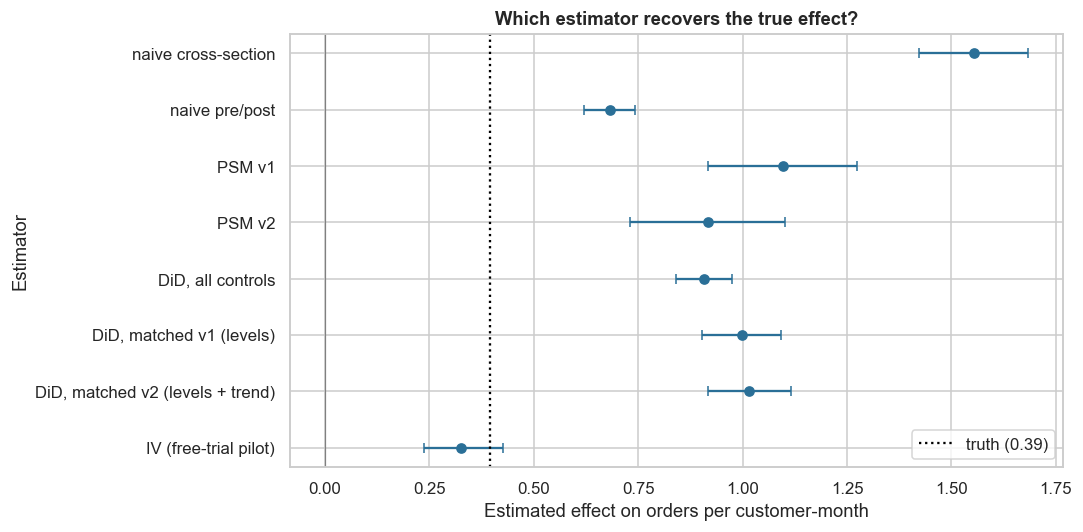

,ATT orders/month,CI low,CI high,error vs truth,CI covers truth,as % of counterfactual
estimator,,,,,,
naive cross-section,1.5530,1.4230,1.6830,1.1590,False,69.8890
naive pre/post,0.6810,0.6200,0.7430,0.2870,False,22.0260
PSM v1,1.0960,0.9180,1.2750,0.7020,False,40.9130
PSM v2,0.9160,0.7310,1.1020,0.5220,False,32.0550
"DiD, all controls",0.9070,0.8400,0.9740,0.5130,False,31.6310
"DiD, matched v1 (levels)",0.9980,0.9030,1.0920,0.6030,False,35.9110
"DiD, matched v2 (levels + trend)",1.0160,0.9160,1.1160,0.6220,False,36.8250
IV (free-trial pilot),0.3260,0.2370,0.4260,-0.0690,True,9.4410


In [12]:
true_att = (OS[T][:, 12:18] - OCFS[T][:, 12:18]).mean(); true_cf = OCFS[T][:, 12:18].mean()
order = ["naive cross-section", "naive pre/post", "PSM v1", "PSM v2", "DiD, all controls", "DiD, matched v1 (levels)", "DiD, matched v2 (levels + trend)", "IV (free-trial pilot)"]
gr = pd.DataFrame([(k, *RES[k], RES[k][0] - true_att, (RES[k][1] <= true_att <= RES[k][2])) for k in order], columns=["estimator", "ATT orders/month", "CI low", "CI high", "error vs truth", "CI covers truth"]).set_index("estimator")
gr["as % of counterfactual"] = gr["ATT orders/month"] / (tpost_mean - gr["ATT orders/month"]) * 100
cf_gap = OCFS[T].mean(0) - OCFS[~T].mean(0)
print(f"Hidden counterfactual gap members − never-members (no-programme world), orders/month: months 0-5 {cf_gap[:6].mean():.2f}, months 6-8 {cf_gap[6:9].mean():.2f}, months 9-11 {cf_gap[9:12].mean():.2f}, months 12-17 {cf_gap[12:18].mean():.2f}; implied DiD bias with window 6-11 → 12-17: {cf_gap[12:18].mean() - cf_gap[6:12].mean():.2f}")
print(f"TRUE effect on launch-month members: {true_att:.3f} orders/month = {true_att / true_cf:.1%} of their counterfactual {true_cf:.2f} orders/month")
fig, ax = plt.subplots(figsize=(10, 5)); yy = np.arange(len(order))[::-1]
ax.errorbar(gr["ATT orders/month"], yy, xerr=[gr["ATT orders/month"] - gr["CI low"], gr["CI high"] - gr["ATT orders/month"]], fmt="o", color="#2a6f97", capsize=3); ax.axvline(true_att, color="black", ls=":", label=f"truth ({true_att:.2f})"); ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(order); ax.set_xlabel("Estimated effect on orders per customer-month"); ax.set_ylabel("Estimator"); ax.set_title("Which estimator recovers the true effect?"); ax.legend()
plt.tight_layout(); plt.show()
gr.round(3)

**Takeaway:** «O76»

### 7.7 The metric that matters: contribution margin, GOV and retention

**(a) Why?** Order frequency is not the objective. Each member order carries a delivery subsidy, and the fee is only ≈ ₹50 a month. We estimate the effect on **GOV**, **contribution margin per customer-month**, and **retention** (ordered in months 15 to 17) with matched v2 DiD (retention is a post-window cross-section because all customers were active before launch). Truth is shown for margin and retention.

#### Code

In [13]:
ti2, ci2 = MT["v2 levels + trend"]; CCFS = CCF.loc[S.index].values; CS_ = C.loc[S.index].values
true_c = (CS_[T][:, 12:18] - CCFS[T][:, 12:18]).mean(); true_ret = ((OS[T][:, 15:18].sum(1) > 0).mean() - (OCFS[T][:, 15:18].sum(1) > 0).mean())
rows = []
for nm, col, tru in (("GOV per month (₹)", "dg", np.nan), ("Contribution margin per month (₹)", "dc", true_c), ("Retained (ordered in months 15-17)", "ret", true_ret)):
    e = att_w(S[col].values, ti2, ci2)
    rows.append((nm, S[col][T].mean() - S[col][~T].mean() if col == "ret" else np.nan, *e, tru))
rows[0] = (rows[0][0], welch(S.gpost[T], S.gpost[~T])[0], *rows[0][2:]); rows[1] = (rows[1][0], welch(S.cpost[T], S.cpost[~T])[0], *rows[1][2:])
mg = pd.DataFrame(rows, columns=["outcome", "naive gap (members − never)", "matched v2 ATT", "CI low", "CI high", "p-value", "true effect (hidden)"]).set_index("outcome")
RES["contribution"] = tuple(mg.loc["Contribution margin per month (₹)", ["matched v2 ATT", "CI low", "CI high"]]); RES["gov"] = tuple(mg.loc["GOV per month (₹)", ["matched v2 ATT", "CI low", "CI high"]]); RES["ret"] = tuple(mg.loc["Retained (ordered in months 15-17)", ["matched v2 ATT", "CI low", "CI high"]])
pre_mpo = S.cpre[T].sum() / S.ypre[T].sum(); fee_m = 149 / 3
print(f"Fee per month ₹{fee_m:.1f}; pre-launch contribution per order of the members ₹{pre_mpo:.1f}; members' mean post orders {tpost_mean:.2f}")
mg.round(4)

Fee per month ₹49.7; pre-launch contribution per order of the members ₹57.7; members' mean post orders 3.78


,naive gap (members − never),matched v2 ATT,CI low,CI high,p-value,true effect (hidden)
outcome,,,,,,
GOV per month (₹),757.0001,520.6003,470.7648,570.4357,0.0000,NaN
Contribution margin per month (₹),30.8257,1.7615,-4.2845,7.8075,0.5680,-37.7287
Retained (ordered in months 15-17),0.1534,0.1316,0.1076,0.1557,0.0000,0.0273


**Observation:** «O77»

### 7.8 Who gains? Heterogeneity in the margin effect (Holm corrected)

**(a) Why?** A membership that loses money on average may still make money for some customers, and design (price, threshold, targeting) should follow. We split members by **fee-paid share** (how often they paid a delivery fee: a sign of price sensitivity) and by **pre-launch frequency**, each into terciles, and estimate the matched v2 margin effect within each group. Six subgroup tests, so **Holm** correction.

#### Code

Hidden mean true frequency lift (log-rate) by fee-paid tercile of members: {'low': 0.046, 'mid': 0.096, 'high': 0.159}


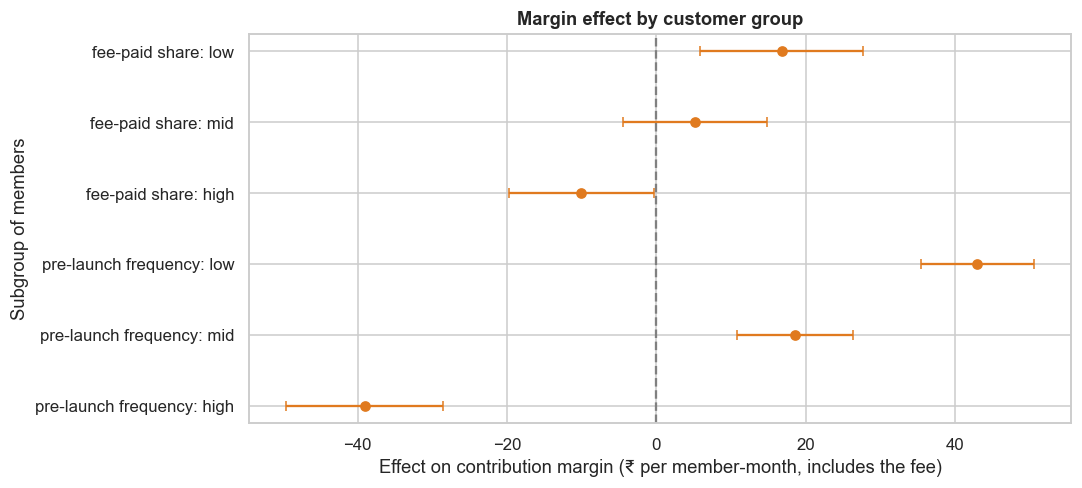

,members,margin ATT ₹/month,CI low,CI high,p-value,p_holm
subgroup (of members),,,,,,
fee-paid share: low,497,16.7801,5.8345,27.7258,0.0027,0.0080
fee-paid share: mid,654,5.2308,-4.4186,14.8801,0.2880,0.2880
fee-paid share: high,824,-10.0507,-19.7270,-0.3743,0.0418,0.0835
pre-launch frequency: low,543,42.9951,35.4151,50.5751,0.0000,0.0000
pre-launch frequency: mid,626,18.5646,10.8164,26.3128,0.0000,0.0000
pre-launch frequency: high,806,-39.0680,-49.5717,-28.5644,0.0000,0.0000


In [14]:
subs = []
for var, lab in (("fee_paid_share", "fee-paid share"), ("o12", "pre-launch frequency")):
    q = pd.qcut(S[var], 3, labels=["low", "mid", "high"]).values
    for g_ in ("low", "mid", "high"):
        k = q[ti2] == g_; e = att_w(S.dc.values, ti2[k], ci2[k]); subs.append((f"{lab}: {g_}", int(k.sum()), *e))
sb = pd.DataFrame(subs, columns=["subgroup (of members)", "members", "margin ATT ₹/month", "CI low", "CI high", "p-value"]).set_index("subgroup (of members)"); sb["p_holm"] = multipletests(sb["p-value"], method="holm")[1]
tau_by = ctruth.loc[S.index[ti2], "_tau"].groupby(pd.qcut(S.fee_paid_share, 3, labels=["low", "mid", "high"]).values[ti2]).mean()
print("Hidden mean true frequency lift (log-rate) by fee-paid tercile of members:", {k: round(v, 3) for k, v in tau_by.items()})
fig, ax = plt.subplots(figsize=(10, 4.6)); yy = np.arange(len(sb))[::-1]
ax.errorbar(sb["margin ATT ₹/month"], yy, xerr=[sb["margin ATT ₹/month"] - sb["CI low"], sb["CI high"] - sb["margin ATT ₹/month"]], fmt="o", color="#e07a1f", capsize=3); ax.axvline(0, color="grey", ls="--")
ax.set_yticks(yy); ax.set_yticklabels(sb.index); ax.set_xlabel("Effect on contribution margin (₹ per member-month, includes the fee)"); ax.set_ylabel("Subgroup of members"); ax.set_title("Margin effect by customer group")
plt.tight_layout(); plt.show()
sb.round(4)

**Takeaway:** «O78»

### 7.9 Power: what would a proper holdout need?

**(a) Why?** The reliable fix is to build the measurement in: keep a **random holdout** that is denied (or delayed) access. We compute the sample size per arm to detect an effect on **orders per month** and on **contribution margin per month**, using the standard deviation of the pre/post change in the data (80% power, α = 0.05, two-sided; the change score removes stable customer differences).

#### Code

In [15]:
sd_o, sd_c = S.dy.std(), S.dc.std(); z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8); rows = []
for lab, sd_, effs in (("orders per month", sd_o, (0.10, 0.20, 0.39)), ("contribution ₹ per month", sd_c, (10, 25, 50))):
    for eff in effs: rows.append((lab, eff, sd_, int(np.ceil(2 * (z * sd_ / eff) ** 2))))
pw = pd.DataFrame(rows, columns=["outcome", "effect to detect", "SD of the change score", "customers per arm"]).set_index(["outcome", "effect to detect"])
print(f"SD of the pre/post change: orders {sd_o:.2f}, contribution ₹{sd_c:.1f}")
pw.round(1)

SD of the pre/post change: orders 1.33, contribution ₹76.1


SD of the change score  customers per arm
outcome                  effect to detect                                           
orders per month         0.1000                            1.3000               2763
                         0.2000                            1.3000                691
                         0.3900                            1.3000                182
contribution ₹ per month 10.0000                          76.1000                911
                         25.0000                          76.1000                146
                         50.0000                          76.1000                 37

**Observation:** «O79»

## 8. ML Section — a small uplift model on the randomised pilot

**What we do:** a **T-learner** (two gradient-boosted regressions with default settings, one fit on invited customers and one on not-invited, predicting the pre/post change in orders), trained on half the pilot and scored on the other half. If the model finds real heterogeneity, the invitation effect among customers it ranks in the top half should exceed that in the bottom half. We also grade the ranking against the hidden true effect. **No tuning.**

#### Code

In [16]:
perm = RNG.permutation(nA); trn, tst = perm[: nA // 2], perm[nA // 2:]; Xa = A[V2].values
m1 = HistGradientBoostingRegressor(random_state=SEED).fit(Xa[trn][Z[trn] == 1], Y[trn][Z[trn] == 1]); m0 = HistGradientBoostingRegressor(random_state=SEED).fit(Xa[trn][Z[trn] == 0], Y[trn][Z[trn] == 0])
tau_hat = m1.predict(Xa[tst]) - m0.predict(Xa[tst]); top = tau_hat >= np.median(tau_hat); zt, yt = Z[tst], Y[tst]
e_top = welch(pd.Series(yt[top & (zt == 1)]), pd.Series(yt[top & (zt == 0)])); e_bot = welch(pd.Series(yt[~top & (zt == 1)]), pd.Series(yt[~top & (zt == 0)]))
dd_ = e_top[0] - e_bot[0]; se_dd = np.sqrt(((e_top[2] - e_top[1]) / 3.92) ** 2 + ((e_bot[2] - e_bot[1]) / 3.92) ** 2)
joined_true = ctruth.loc[A.index[tst], "_tau"].values; rho = stats.spearmanr(tau_hat, joined_true)[0]
print(f"Invitation effect on orders/month (ITT) among predicted top half: {e_top[0]:.3f} (CI {e_top[1]:.3f} to {e_top[2]:.3f}); bottom half: {e_bot[0]:.3f} (CI {e_bot[1]:.3f} to {e_bot[2]:.3f})")
print(f"Top − bottom difference: {dd_:.3f} (SE {se_dd:.3f}, p = {2 * stats.norm.sf(abs(dd_ / se_dd)):.2g}); Spearman of predicted uplift with the hidden true effect: {rho:+.3f}")

Invitation effect on orders/month (ITT) among predicted top half: 0.094 (CI 0.035 to 0.153); bottom half: 0.059 (CI 0.001 to 0.116)
Top − bottom difference: 0.035 (SE 0.042, p = 0.4); Spearman of predicted uplift with the hidden true effect: +0.180


**Observation:** «O8»

## 9. Business Translation — ₹ impact

Assumptions (D-21-08): **9 lakh members** (the documented company-reported scale one month after the relaunch, used here only as a size for the simulated programme); the per-member monthly effect is the matched v2 estimate of contribution margin (fee, subsidy and extra orders netted), held constant for 12 months. Best and worst use the confidence interval. The "targeted" scenario enrols only the highest fee-paid tercile (a third of members) at that group's estimated effect. The "naive claim" is what the post-launch order gap would have implied, valued at the members' pre-launch margin per order.

#### Code

In [17]:
MEMB = 9e5; cr = lambda per_month, n=MEMB: per_month * 12 * n / 1e7
base, lo_c, hi_c = RES["contribution"]; naive_orders = RES["naive cross-section"][0]
hi_row = sb.loc["fee-paid share: high"]
biz = pd.DataFrame({"₹ crore / year": [cr(lo_c), cr(base), cr(hi_c), cr(hi_row["margin ATT ₹/month"], MEMB / 3), cr(naive_orders * pre_mpo)]},
                   index=["Worst (CI low)", "Base (matched v2 ATT)", "Best (CI high)", "Targeted to high fee-paid tercile (base)", "Naive claim (post-launch gap × pre-launch margin per order)"])
biz["per member per month (₹)"] = [lo_c, base, hi_c, hi_row["margin ATT ₹/month"], naive_orders * pre_mpo]
be_fee3 = 3 * (fee_m - base)
print(f"Break-even fee for the average member: ₹{fee_m - base:.0f} a month = ₹{be_fee3:.0f} per three months (now ₹149)")
biz.round(2)

Break-even fee for the average member: ₹48 a month = ₹144 per three months (now ₹149)


,₹ crore / year,per member per month (₹)
Worst (CI low),-4.6300,-4.2800
Base (matched v2 ATT),1.9000,1.7600
Best (CI high),8.4300,7.8100
Targeted to high fee-paid tercile (base),-3.6200,-10.0500
Naive claim (post-launch gap × pre-launch margin per order),96.7100,89.5500


**Takeaway (business reading):** «O9»

## 10. Recommendation and Decision

«O10»

## 11. Risks, Limitations and Next Steps

- **Evidence is weak:** no company method is public. The design facts come from press coverage; the shareholder-letter PDFs were not retrievable; figures from search snippets are not used. All numbers here come from a simulation that we built, so they show how the methods behave, not what Zomato or Flipkart found.
- **Matching only handles what we observe:** conditional independence cannot be tested. The grading in 7.6 is possible only because we simulated the truth; in real data use placebo tests, sensitivity analysis and, above all, a holdout.
- **Parallel trends:** members were on a different trajectory before launch. DiD is trustworthy only after trend is handled and the pre-launch event study is flat.
- **Controls chosen with hindsight:** "never joined" conditions on the future. A not-yet-treated design (staggered DiD with modern estimators) is the next step for a multi-month rollout.
- **Constant effect and no churn of members:** we assume a stable effect and members who stay. Real programmes see renewal churn and the end of the introductory price; the margin should be re-estimated at the renewal price.
- **Margin inputs are assumed:** delivery subsidy, margin rate and the fee path are our assumptions. Restaurant-partner funding of discounts, and effects on non-members (cannibalisation), are not in the model.
- **Next steps:** a persistent random holdout; a regression discontinuity on tier thresholds for earned tiers (Flipkart Plus style, 15 and 25 transactions in 365 days); a synthetic-control or geo design if a holdout is impossible; long-run retention and renewal analysis.

## 12. Appendix

| Quantity | Formula |
|---|---|
| ATT | E[Y(1) − Y(0) \| member] |
| Propensity score | e(x) = P(join \| pre-launch covariates x) |
| Standardised mean difference | (mean_T − mean_C) / √((var_T + var_C) / 2) |
| Matched ATT | mean(y_treated) − Σ w_j y_j / n, w_j = times control j is used |
| Difference-in-differences | (Ȳ_T,post − Ȳ_T,pre) − (Ȳ_C,post − Ȳ_C,pre) |
| Wald / IV estimate | (E[Y\|Z=1] − E[Y\|Z=0]) / (E[D\|Z=1] − E[D\|Z=0]) |
| First-stage F | (first-stage difference / its SE)² |
| Sample size per arm | 2 (z_{α/2} + z_β)² σ² / δ² |
| Break-even fee | fee − (effect on contribution margin), per member-month |

| Term | Meaning |
|---|---|
| Selection bias | Members differ from non-members before the programme |
| Parallel trends | Without treatment both groups would have changed by the same amount |
| Placebo test | The same analysis on a fake launch or a pre-period, where the effect must be zero |
| Instrument | Randomised nudge that changes joining but affects orders only through joining |
| Complier | Customer who joins because of the nudge |
| ATT | Average effect on the customers who actually joined |
| Contribution margin | Revenue minus variable costs, here after delivery subsidy and including the membership fee |
| Holdout | A random group denied the programme to give the counterfactual |